# Pilot Parameter Sweep

**Eval plan Step 3** — Find 2–3 parameter regimes where H1 and H2 are clearly observable.

**H1**: TCT users survive significantly more rounds than IDP before budget exhaustion.  
**H2**: Empirical private accesses per hit stay below K_k (and are close — bound is non-vacuous).

**Sweep axes:** epsilon × delta × target_hit_rate × population (alpha, beta)  
**Fixed:** N=200 users, 500 rounds, eps_budget=30, seed=0

**Primary H1 metric:** `half_life_gap` = round where TCT drops below 50% active minus round where IDP does.  
Positive = TCT users survive longer. Large positive = clear H1 signal.

In [1]:
import sys
sys.path.insert(0, '..')

import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_dp import StandardDPAccountant
from simulation.calibration import q_from_epsilon, set_threshold_for_hit_rate
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.environment import SimulationEnvironment

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})


def heatmap(ax, pivot_df, title, fmt='.0f', vmin=None, vmax=None):
    """Annotated heatmap using imshow (no seaborn dependency)."""
    data = pivot_df.values.astype(float)
    v_lo = data.min() if vmin is None else vmin
    v_hi = data.max() if vmax is None else vmax
    im = ax.imshow(data, cmap='RdYlGn', vmin=v_lo, vmax=v_hi, aspect='auto')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks(range(len(pivot_df.columns)))
    ax.set_xticklabels(pivot_df.columns)
    ax.set_yticks(range(len(pivot_df.index)))
    ax.set_yticklabels(pivot_df.index)
    ax.set_xlabel(pivot_df.columns.name)
    ax.set_ylabel(pivot_df.index.name)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, format(data[i, j], fmt), ha='center', va='center',
                    fontsize=10, color='black')
    ax.set_title(title, fontsize=11)

In [ ]:
# ── Fixed simulation parameters ──────────────────────────────────────────────
N_USERS      = 200
N_ROUNDS     = 300
EPS_BUDGET   = 1.0
DELTA_BUDGET = 1.0
SEED         = 0

# ── Sweep axes ────────────────────────────────────────────────────────────────
EPSILONS  = [0.005, 0.01, 0.02]
DELTAS    = [1e-5, 1e-6]
HIT_RATES = [0.02, 0.05, 0.10]
POPS = [
    {'name': 'SPARSE',   'alpha': 0.3, 'beta': 3.0},   # E[rate] ≈ 0.091
    {'name': 'MODERATE', 'alpha': 0.5, 'beta': 2.0},   # E[rate] ≈ 0.200
]

total = len(EPSILONS) * len(DELTAS) * len(HIT_RATES) * len(POPS)
print(f'Total combinations: {total}')
print(f'IDP depletion rounds: ε=0.005→{int(EPS_BUDGET/0.005)}, ε=0.01→{int(EPS_BUDGET/0.01)}, ε=0.02→{int(EPS_BUDGET/0.02)}')

## Section 1: Run Sweep

In [3]:
def half_life(active_fractions, threshold=0.5):
    """First round where active fraction drops below threshold; else final round."""
    for i, f in enumerate(active_fractions):
        if f < threshold:
            return i
    return len(active_fractions) - 1


def run_combo(epsilon, delta, target_hit_rate, alpha, beta, seed=SEED):
    config = PopulationConfig(
        n_users=N_USERS, alpha=alpha, beta=beta,
        epsilon_budget=EPS_BUDGET, delta_budget=DELTA_BUDGET,
    )
    calib_pop = generate_synthetic_population(config, rng=np.random.default_rng(seed))
    threshold, actual_hr = set_threshold_for_hit_rate(
        calib_pop, epsilon=epsilon, target_hit_rate=target_hit_rate,
        n_pilot=1000, rng=np.random.default_rng(seed + 9999),
    )

    pop_tct = generate_synthetic_population(config, rng=np.random.default_rng(seed))
    pop_idp = generate_synthetic_population(config, rng=np.random.default_rng(seed))

    acc_tct = AdaptiveTCTAccountant(epsilon=epsilon, delta=delta)
    res_tct = SimulationEnvironment(
        population=pop_tct, accountant=acc_tct, threshold=threshold,
        query_epsilon=epsilon, num_rounds=N_ROUNDS, rng=np.random.default_rng(seed),
    ).run()

    acc_idp = StandardDPAccountant(epsilon_per_round=epsilon, delta_per_round=0.0)
    res_idp = SimulationEnvironment(
        population=pop_idp, accountant=acc_idp, threshold=threshold,
        query_epsilon=epsilon, num_rounds=N_ROUNDS, rng=np.random.default_rng(seed),
    ).run()

    tct_active = res_tct.active_fraction_by_round()
    idp_active = res_idp.active_fraction_by_round()

    acc_ref = AdaptiveTCTAccountant(epsilon=epsilon, delta=delta)
    k1_cost = acc_ref.compositions(1) * epsilon

    return {
        'epsilon': epsilon, 'delta': delta,
        'target_hit_rate': target_hit_rate, 'actual_hit_rate': round(actual_hr, 3),
        'alpha': alpha, 'beta': beta,
        'q': round(q_from_epsilon(epsilon), 4),
        'k1_cost': round(k1_cost, 2),
        'idp_depletion': int(EPS_BUDGET / epsilon),
        'half_life_tct': half_life(tct_active),
        'half_life_idp': half_life(idp_active),
        'half_life_gap': half_life(tct_active) - half_life(idp_active),
        'tct_final_active': round(tct_active[-1], 3),
        'idp_final_active': round(idp_active[-1], 3),
        'retention_gap': round(tct_active[-1] - idp_active[-1], 3),
        '_tct_active': tct_active,
        '_idp_active': idp_active,
        '_tct_avg_eps': res_tct.avg_epsilon_remaining_by_round(),
        '_idp_avg_eps': res_idp.avg_epsilon_remaining_by_round(),
    }


print('Running sweep...', flush=True)
records = []
for pop, eps, dlt, hr in itertools.product(POPS, EPSILONS, DELTAS, HIT_RATES):
    r = run_combo(eps, dlt, hr, pop['alpha'], pop['beta'])
    r['pop'] = pop['name']
    records.append(r)
    print(f"  {pop['name']:8s} ε={eps} δ={dlt:.0e} hr={hr}  "
          f"half_life_gap={r['half_life_gap']:+4d}  ret_gap={r['retention_gap']:+.3f}",
          flush=True)

df = pd.DataFrame(records)
print(f'\nDone. {len(df)} combinations.')

Running sweep...
  SPARSE   ε=0.1 δ=1e-02 hr=0.02  half_life_gap=+200  ret_gap=+1.000
  SPARSE   ε=0.1 δ=1e-02 hr=0.05  half_life_gap=+200  ret_gap=+1.000
  SPARSE   ε=0.1 δ=1e-02 hr=0.1  half_life_gap=+200  ret_gap=+1.000
  SPARSE   ε=0.1 δ=1e-03 hr=0.02  half_life_gap=+200  ret_gap=+1.000
  SPARSE   ε=0.1 δ=1e-03 hr=0.05  half_life_gap=+200  ret_gap=+1.000
  SPARSE   ε=0.1 δ=1e-03 hr=0.1  half_life_gap=+200  ret_gap=+1.000
  SPARSE   ε=0.3 δ=1e-02 hr=0.02  half_life_gap=+400  ret_gap=+0.980
  SPARSE   ε=0.3 δ=1e-02 hr=0.05  half_life_gap=+400  ret_gap=+0.960
  SPARSE   ε=0.3 δ=1e-02 hr=0.1  half_life_gap=+400  ret_gap=+0.920
  SPARSE   ε=0.3 δ=1e-03 hr=0.02  half_life_gap=+400  ret_gap=+0.975
  SPARSE   ε=0.3 δ=1e-03 hr=0.05  half_life_gap=+400  ret_gap=+0.940
  SPARSE   ε=0.3 δ=1e-03 hr=0.1  half_life_gap=+400  ret_gap=+0.920
  SPARSE   ε=0.5 δ=1e-02 hr=0.02  half_life_gap=+440  ret_gap=+0.925
  SPARSE   ε=0.5 δ=1e-02 hr=0.05  half_life_gap=+440  ret_gap=+0.920
  SPARSE   ε=0.5 δ=1e

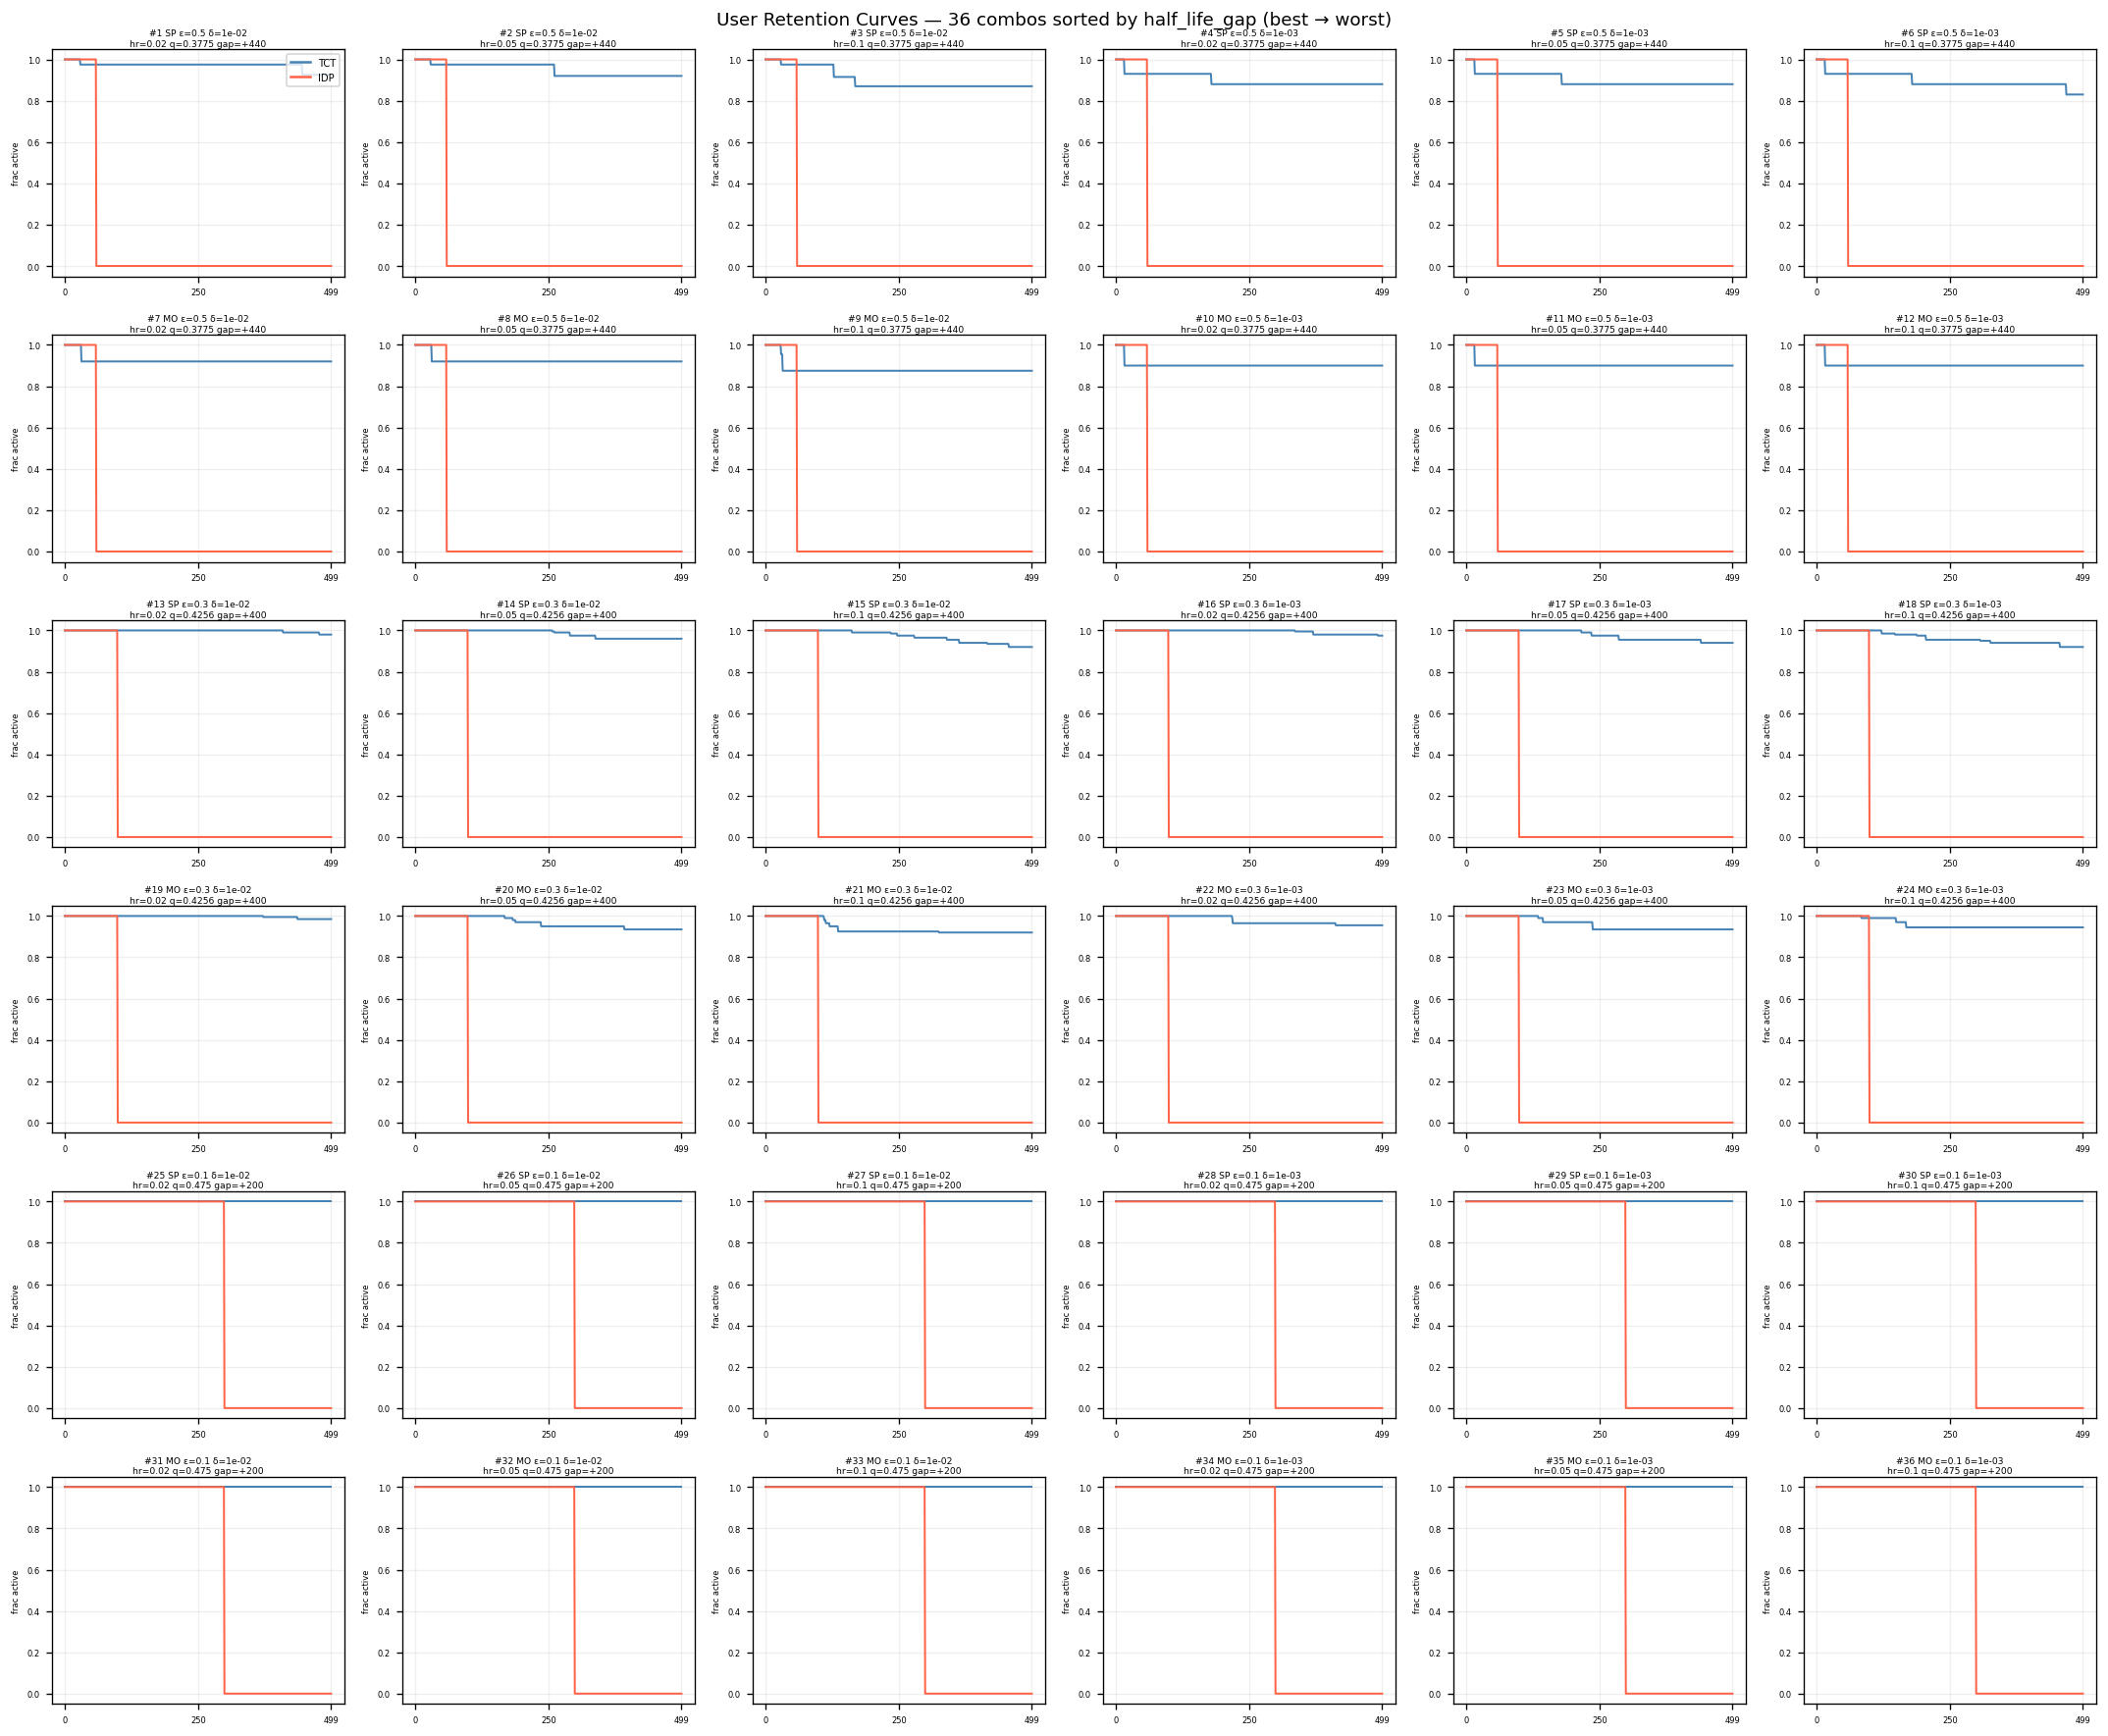

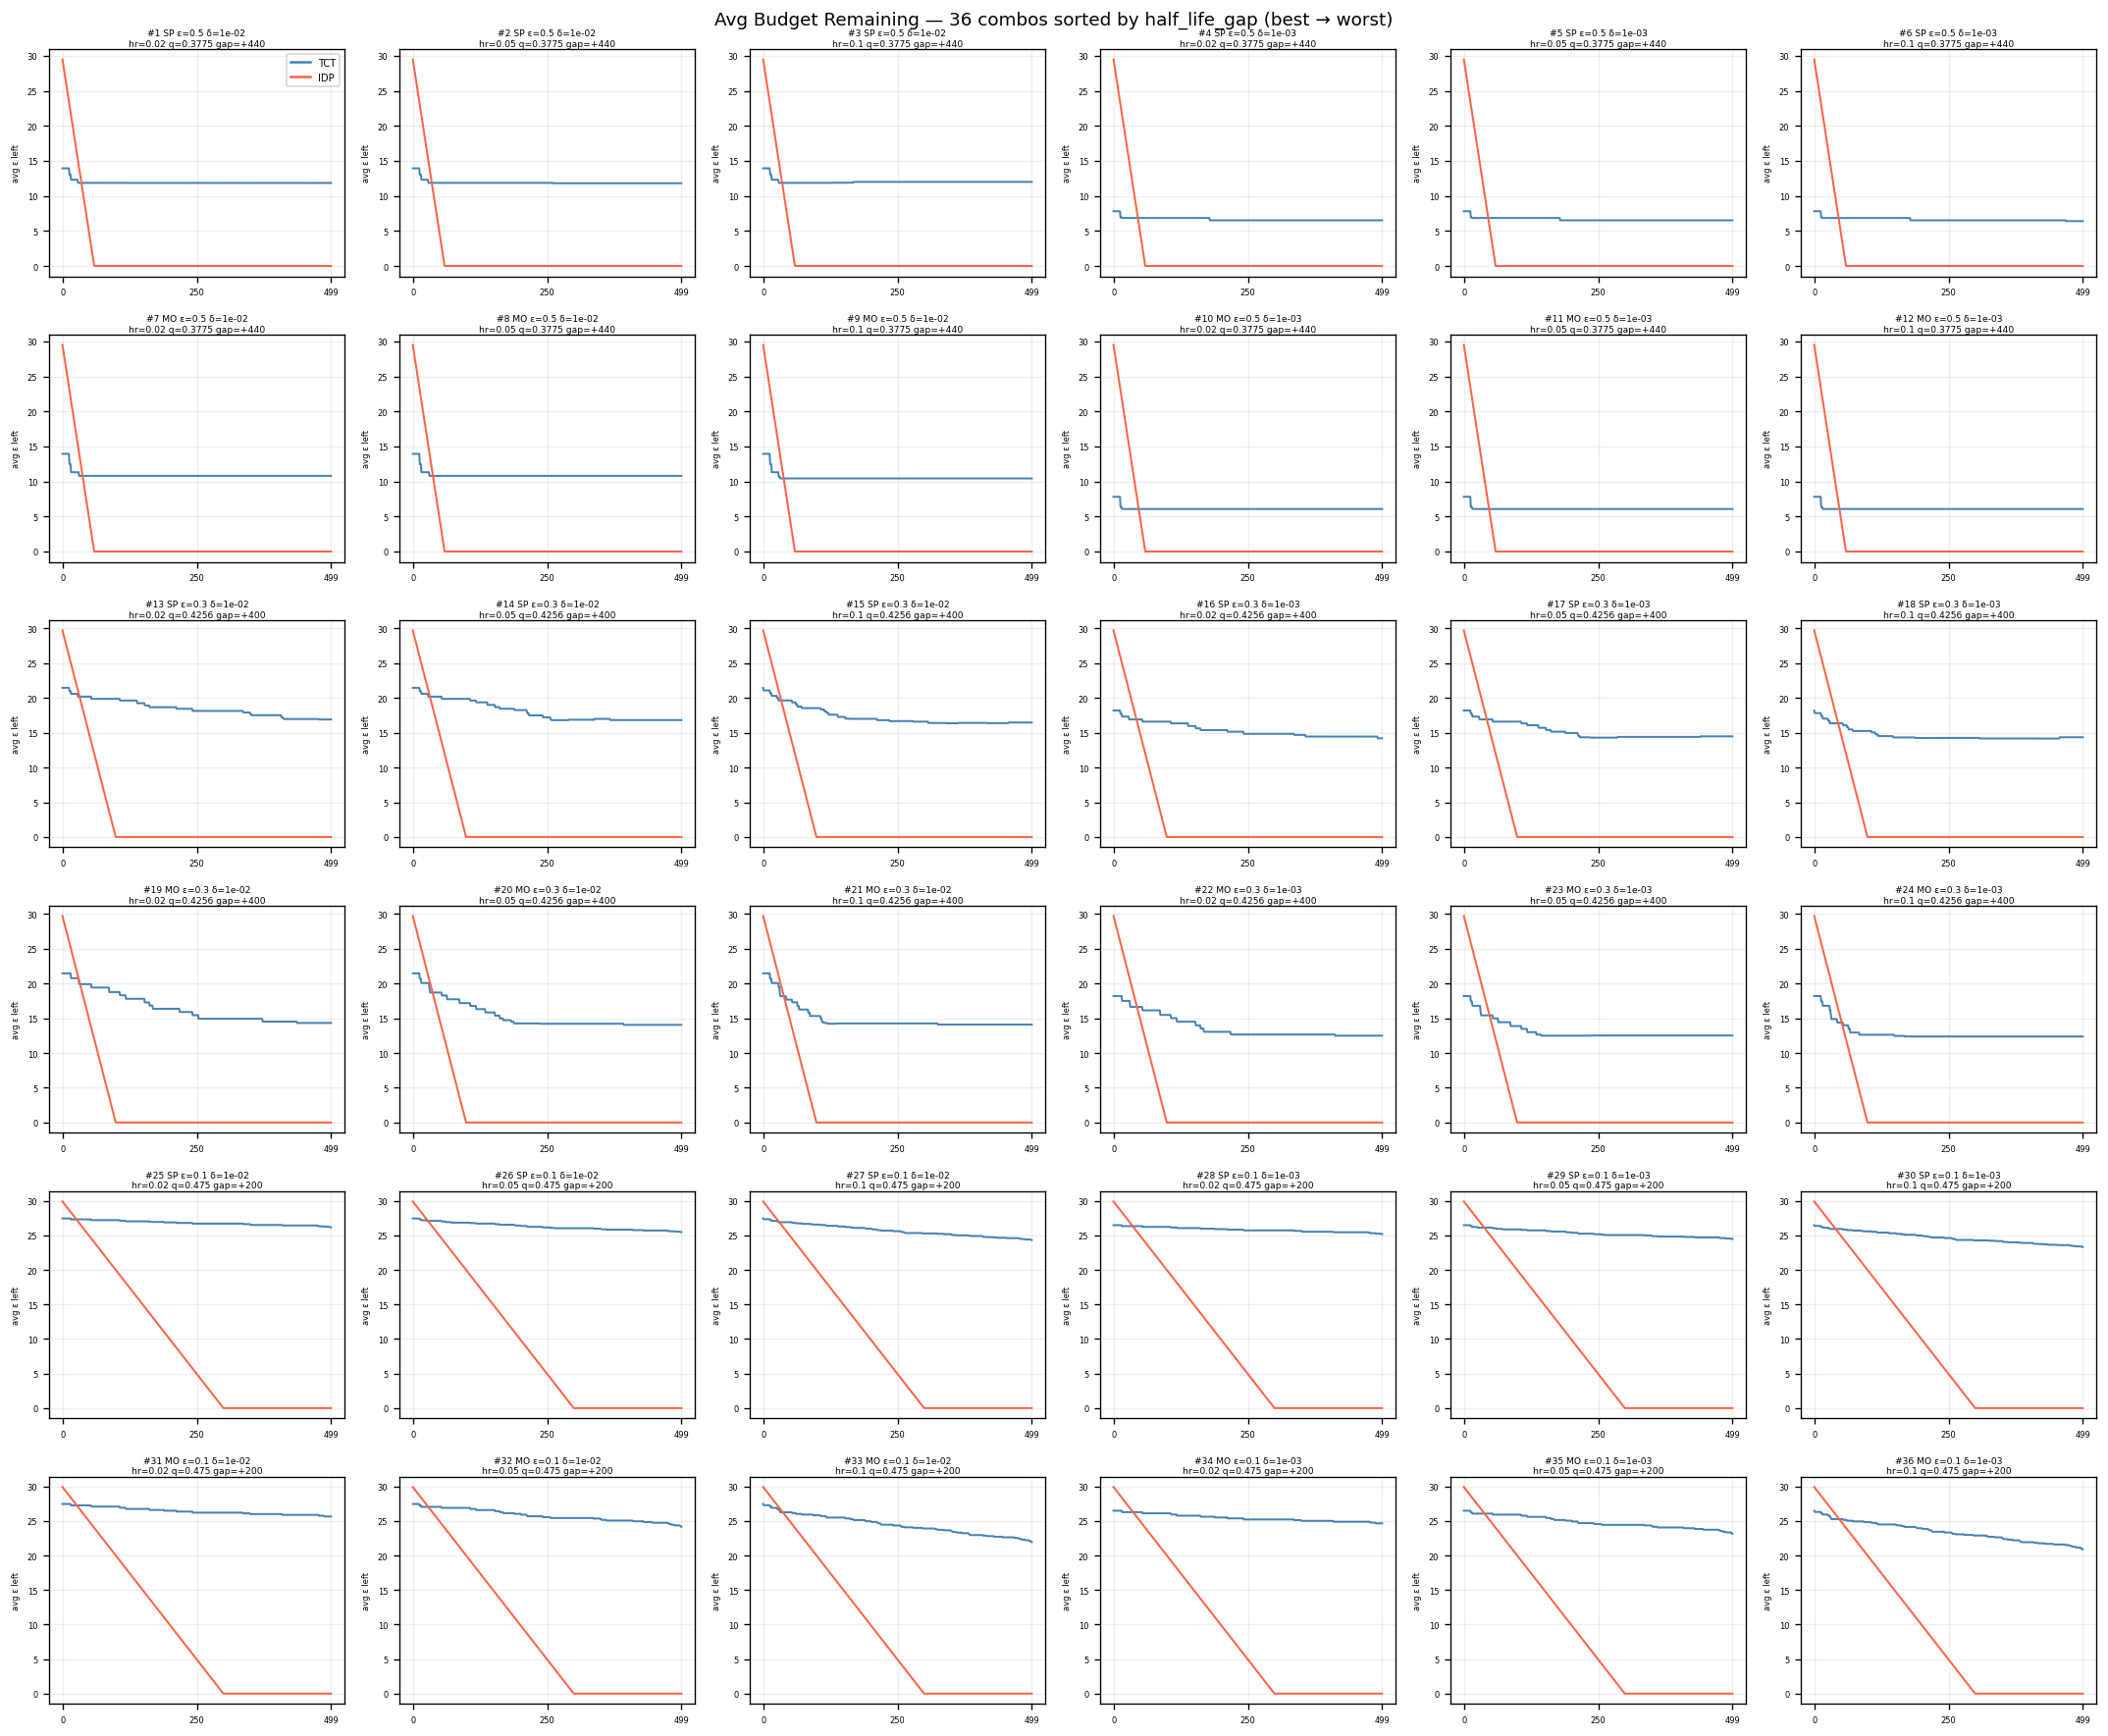

In [4]:
# All 36 retention curves + avg budget curves, sorted by half_life_gap best→worst
sorted_recs = sorted(records, key=lambda r: r['half_life_gap'], reverse=True)

def pop_short(r):
    return 'SP' if r['pop'] == 'SPARSE' else 'MO'

def make_grid(key_tct, key_idp, ylabel, title_prefix):
    fig, axes = plt.subplots(6, 6, figsize=(18, 15))
    for idx, r in enumerate(sorted_recs):
        ax = axes[idx // 6][idx % 6]
        tct_curve = r[key_tct]
        idp_curve = r[key_idp]
        n = max(len(tct_curve), len(idp_curve))
        tct_pad = tct_curve + [tct_curve[-1]] * (n - len(tct_curve))
        idp_pad = idp_curve + [idp_curve[-1]] * (n - len(idp_curve))
        rnds = list(range(n))
        ax.plot(rnds, tct_pad, color='steelblue', lw=1.2)
        ax.plot(rnds, idp_pad, color='tomato',    lw=1.2)
        ax.tick_params(labelsize=5)
        ax.set_xticks([0, n // 2, n - 1])
        ax.grid(True, alpha=0.2)
        rank = idx + 1
        ax.set_title(
            f"#{rank} {pop_short(r)} ε={r['epsilon']} δ={r['delta']:.0e}\n"
            f"hr={r['target_hit_rate']} q={r['q']} gap={r['half_life_gap']:+d}",
            fontsize=5.5, pad=2
        )
        ax.set_ylabel(ylabel, fontsize=5)
    # Shared legend
    axes[0][0].plot([], [], color='steelblue', lw=1.5, label='TCT')
    axes[0][0].plot([], [], color='tomato',    lw=1.5, label='IDP')
    axes[0][0].legend(fontsize=6, loc='upper right')
    fig.suptitle(f'{title_prefix} — 36 combos sorted by half_life_gap (best → worst)', fontsize=11)
    plt.tight_layout()
    plt.show()

make_grid('_tct_active', '_idp_active',    'frac active',  'User Retention Curves')
make_grid('_tct_avg_eps', '_idp_avg_eps',  'avg ε left',   'Avg Budget Remaining')


## Section 2: Summary Table

In [5]:
display_cols = ['pop', 'epsilon', 'delta', 'target_hit_rate', 'q', 'k1_cost',
                'idp_depletion', 'half_life_tct', 'half_life_idp',
                'half_life_gap', 'retention_gap']

summary = df[display_cols].sort_values('half_life_gap', ascending=False)

def highlight_gap(val):
    if isinstance(val, (int, float)):
        if val > 200: return 'background-color: #90ee90'
        if val > 100: return 'background-color: #ffffcc'
        if val < 0:   return 'background-color: #ffcccc'
    return ''

summary.style \
    .applymap(highlight_gap, subset=['half_life_gap']) \
    .format({'delta': '{:.0e}', 'k1_cost': '{:.2f}',
             'retention_gap': '{:+.3f}', 'half_life_gap': '{:+d}'}) \
    .set_caption('Sweep results — sorted by half_life_gap (green >200, yellow >100, red <0)')

/var/folders/tb/6fc029qd3xqgsdzv9hz5fltc0000gn/T/ipykernel_68999/1450174026.py:14: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  summary.style \


,pop,epsilon,delta,target_hit_rate,q,k1_cost,idp_depletion,half_life_tct,half_life_idp,half_life_gap,retention_gap
35,MODERATE,0.500000,1e-03,0.100000,0.377500,22.18,60,499,59,+440,+0.900
13,SPARSE,0.500000,1e-02,0.050000,0.377500,16.06,60,499,59,+440,+0.920
30,MODERATE,0.500000,1e-02,0.020000,0.377500,16.06,60,499,59,+440,+0.920
17,SPARSE,0.500000,1e-03,0.100000,0.377500,22.18,60,499,59,+440,+0.830
16,SPARSE,0.500000,1e-03,0.050000,0.377500,22.18,60,499,59,+440,+0.880
15,SPARSE,0.500000,1e-03,0.020000,0.377500,22.18,60,499,59,+440,+0.880
14,SPARSE,0.500000,1e-02,0.100000,0.377500,16.06,60,499,59,+440,+0.870
12,SPARSE,0.500000,1e-02,0.020000,0.377500,16.06,60,499,59,+440,+0.925
31,MODERATE,0.500000,1e-02,0.050000,0.377500,16.06,60,499,59,+440,+0.920
32,MODERATE,0.500000,1e-02,0.100000,0.377500,16.06,60,499,59,+440,+0.875


## Section 3: Heatmaps

`half_life_gap` as a function of (epsilon, target_hit_rate) for each (population × delta).  
Positive = TCT half-life exceeds IDP half-life by that many rounds.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for (i, pop_name), (j, dlt) in itertools.product(
    enumerate(['SPARSE', 'MODERATE']), enumerate(DELTAS)
):
    sub = df[(df['pop'] == pop_name) & (df.delta == dlt)]
    pivot = sub.pivot(index='target_hit_rate', columns='epsilon', values='half_life_gap')
    heatmap(axes[i][j], pivot,
            title=f'{pop_name}  |  δ={dlt:.0e}',
            fmt='.0f')

plt.suptitle(
    f'H1 metric: half_life_gap (rounds TCT survives longer than IDP)\n'
    f'N={N_USERS}, budget={EPS_BUDGET}, rounds={N_ROUNDS}',
    fontsize=12, y=1.02
)
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for (i, pop_name), (j, dlt) in itertools.product(
    enumerate(['SPARSE', 'MODERATE']), enumerate(DELTAS)
):
    sub = df[(df['pop'] == pop_name) & (df.delta == dlt)]
    pivot = sub.pivot(index='target_hit_rate', columns='epsilon', values='retention_gap')
    heatmap(axes[i][j], pivot,
            title=f'{pop_name}  |  δ={dlt:.0e}',
            fmt='.2f')

plt.suptitle(
    f'Final active fraction: TCT − IDP  (at round {N_ROUNDS})\n'
    'Positive = TCT has more survivors at end of experiment',
    fontsize=12, y=1.02
)
plt.tight_layout()
plt.show()

## Section 4: Detailed Retention Curves for Top Settings

Full retention curves for the 4 settings with the largest `half_life_gap`.

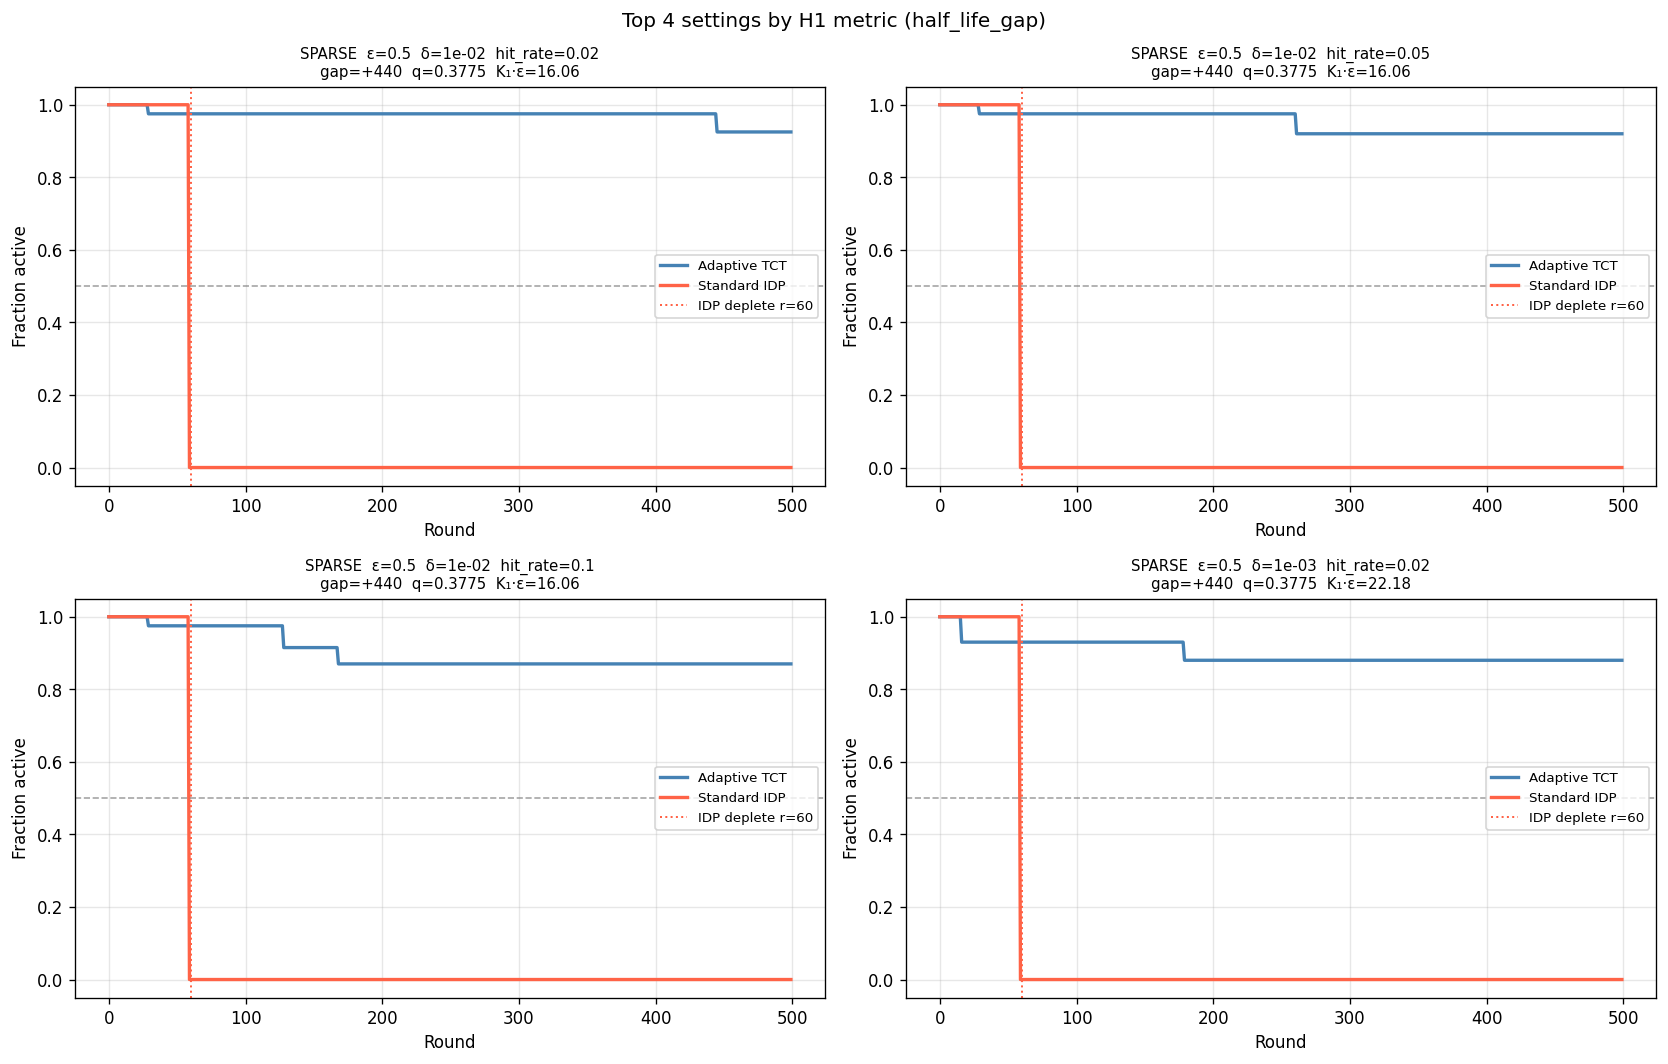

In [8]:
top4 = df.nlargest(4, 'half_life_gap').reset_index(drop=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for idx, row in top4.iterrows():
    ax = axes[idx // 2][idx % 2]

    tct_active = row['_tct_active']
    idp_active = row['_idp_active']
    rounds_tct = list(range(len(tct_active)))

    ax.plot(rounds_tct, tct_active, color='steelblue', linewidth=2, label='Adaptive TCT')

    # Pad IDP to same length (zeros after all users deplete)
    idp_padded = idp_active + [idp_active[-1]] * (len(tct_active) - len(idp_active))
    ax.plot(rounds_tct, idp_padded, color='tomato', linewidth=2, label='Standard IDP')

    ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, alpha=0.7)
    ax.axvline(row['idp_depletion'], color='tomato', linestyle=':', linewidth=1.2,
               label=f"IDP deplete r={row['idp_depletion']}")

    ax.set_xlabel('Round')
    ax.set_ylabel('Fraction active')
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_title(
        f"{row['pop']}  ε={row['epsilon']}  δ={row['delta']:.0e}  hit_rate={row['target_hit_rate']}\n"
        f"gap={row['half_life_gap']:+d}  q={row['q']}  K₁·ε={row['k1_cost']:.2f}",
        fontsize=9
    )

plt.suptitle('Top 4 settings by H1 metric (half_life_gap)', fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
print('Top 4 settings:\n')
for _, row in top4.iterrows():
    print(f"  {row['pop']}  ε={row['epsilon']}  δ={row['delta']:.0e}  hit_rate={row['target_hit_rate']}")
    print(f"    q={row['q']}  K₁·ε={row['k1_cost']:.2f}  IDP depletion={row['idp_depletion']}")
    print(f"    half_life_gap={row['half_life_gap']:+d}  retention_gap={row['retention_gap']:+.3f}")
    print()

Top 4 settings:

  SPARSE  ε=0.5  δ=1e-02  hit_rate=0.02
    q=0.3775  K₁·ε=16.06  IDP depletion=60
    half_life_gap=+440  retention_gap=+0.925

  SPARSE  ε=0.5  δ=1e-02  hit_rate=0.05
    q=0.3775  K₁·ε=16.06  IDP depletion=60
    half_life_gap=+440  retention_gap=+0.920

  SPARSE  ε=0.5  δ=1e-02  hit_rate=0.1
    q=0.3775  K₁·ε=16.06  IDP depletion=60
    half_life_gap=+440  retention_gap=+0.870

  SPARSE  ε=0.5  δ=1e-03  hit_rate=0.02
    q=0.3775  K₁·ε=22.18  IDP depletion=60
    half_life_gap=+440  retention_gap=+0.880



## Section 5: H2 Sanity Check

For the top-1 setting, run 50 independent trials to check the prepaid bound K_k.

In each trial: record R_k = round number of the k-th threshold crossing.  
The bound says R_k ≤ K_k with probability ≥ 1 − δ.  
**Left plot**: empirical R_k distribution vs K_k.  
**Right plot**: empirical failure rate (should be ≤ δ).

In [10]:
best = top4.iloc[0]
eps, dlt, hr = best['epsilon'], best['delta'], best['target_hit_rate']
alpha, beta  = best['alpha'], best['beta']

print(f"H2 check: pop={best['pop']}, ε={eps}, δ={dlt:.0e}, hit_rate={hr}")
print(f"q={best['q']}, K₁·ε={best['k1_cost']:.2f}")

N_TRIALS = 50
MAX_HITS = 15

config = PopulationConfig(
    n_users=N_USERS, alpha=alpha, beta=beta,
    epsilon_budget=EPS_BUDGET, delta_budget=DELTA_BUDGET,
)
calib_pop = generate_synthetic_population(config, rng=np.random.default_rng(SEED))
threshold, _ = set_threshold_for_hit_rate(
    calib_pop, epsilon=eps, target_hit_rate=hr,
    n_pilot=1000, rng=np.random.default_rng(SEED + 9999),
)

acc_ref  = AdaptiveTCTAccountant(epsilon=eps, delta=dlt)
K_bounds = {k: acc_ref.compositions(k) for k in range(1, MAX_HITS + 1)}
R_k      = {k: [] for k in range(1, MAX_HITS + 1)}

for trial in range(N_TRIALS):
    s = 1000 + trial
    pop = generate_synthetic_population(config, rng=np.random.default_rng(s))
    for u in pop.active_users:        # infinite budget — observe all hits
        u.epsilon_budget = 1e9
    acc = AdaptiveTCTAccountant(epsilon=eps, delta=dlt)
    res = SimulationEnvironment(
        population=pop, accountant=acc, threshold=threshold,
        query_epsilon=eps, num_rounds=N_ROUNDS, rng=np.random.default_rng(s),
    ).run()
    tops = sorted(r.round_num for r in res.rounds if r.is_top)
    for k in range(1, MAX_HITS + 1):
        if len(tops) >= k:
            R_k[k].append(tops[k - 1])

print(f'\nTrials: {N_TRIALS}  |  Avg hits/trial: {np.mean([len(R_k[k]) for k in R_k]):.1f}')

H2 check: pop=SPARSE, ε=0.5, δ=1e-02, hit_rate=0.02
q=0.3775, K₁·ε=16.06

Trials: 50  |  Avg hits/trial: 7.9


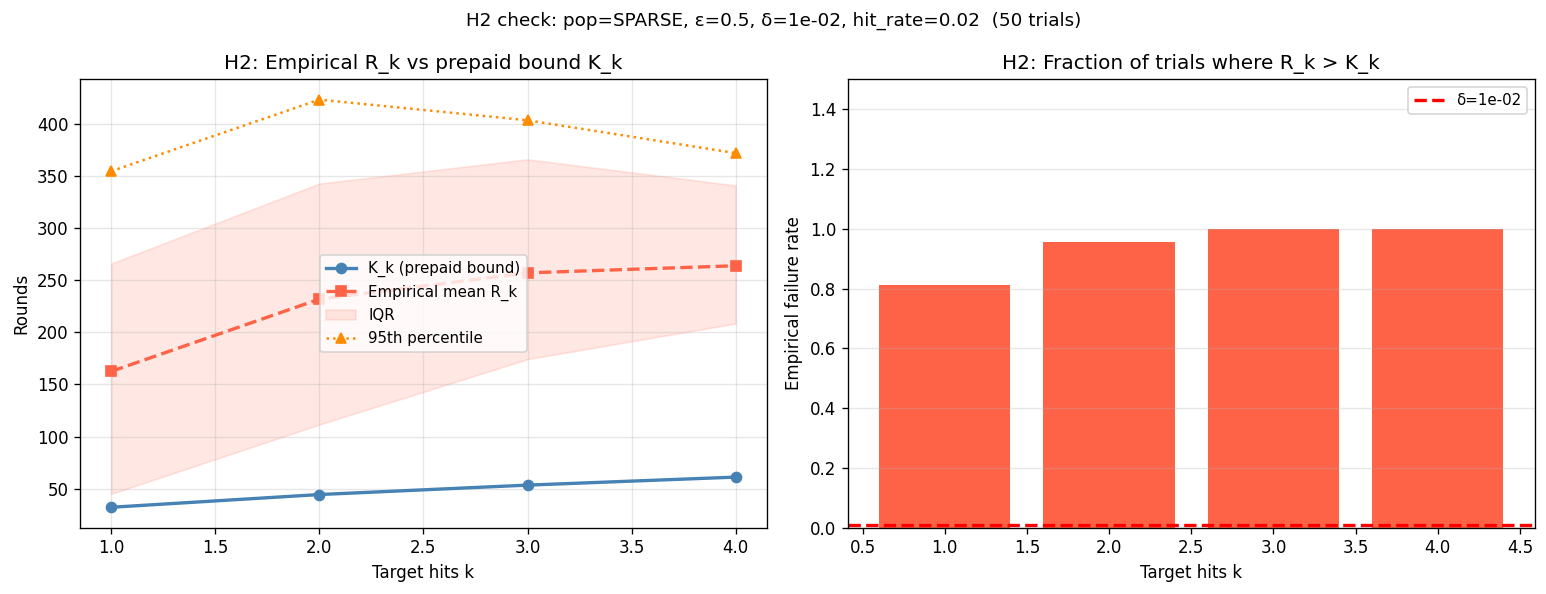

Max failure rate: 1.000  (δ=1e-02)
H2 WARN — check params or increase N_TRIALS

Tightness (R_k mean / K_k — closer to 1 = bound is non-vacuous):
  k= 1: mean=162  K_k=32  ratio=5.060
  k= 2: mean=232  K_k=44  ratio=5.229
  k= 3: mean=257  K_k=53  ratio=4.816
  k= 4: mean=264  K_k=61  ratio=4.321


In [11]:
k_vals  = [k for k in range(1, MAX_HITS + 1) if len(R_k[k]) >= 10]
emp_mean = [np.mean(R_k[k])         for k in k_vals]
emp_p95  = [np.percentile(R_k[k], 95) for k in k_vals]
theory   = [K_bounds[k]             for k in k_vals]
fail_r   = [np.mean(np.array(R_k[k]) > K_bounds[k]) for k in k_vals]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(k_vals, theory,   'o-', color='steelblue', lw=2, label='K_k (prepaid bound)')
ax.plot(k_vals, emp_mean, 's--', color='tomato',   lw=2, label='Empirical mean R_k')
ax.fill_between(k_vals,
    [np.percentile(R_k[k], 25) for k in k_vals],
    [np.percentile(R_k[k], 75) for k in k_vals],
    color='tomato', alpha=0.15, label='IQR')
ax.plot(k_vals, emp_p95, '^:', color='darkorange', lw=1.5, label='95th percentile')
ax.set_xlabel('Target hits k')
ax.set_ylabel('Rounds')
ax.set_title('H2: Empirical R_k vs prepaid bound K_k')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
colors = ['tomato' if f > dlt else 'steelblue' for f in fail_r]
ax.bar(k_vals, fail_r, color=colors)
ax.axhline(dlt, color='red', linestyle='--', lw=2, label=f'δ={dlt:.0e}')
ax.set_xlabel('Target hits k')
ax.set_ylabel('Empirical failure rate')
ax.set_title('H2: Fraction of trials where R_k > K_k')
ax.set_ylim(0, max(max(fail_r) * 1.5, dlt * 3))
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle(
    f"H2 check: pop={best['pop']}, ε={eps}, δ={dlt:.0e}, hit_rate={hr}  ({N_TRIALS} trials)",
    fontsize=11
)
plt.tight_layout()
plt.show()

print(f'Max failure rate: {max(fail_r):.3f}  (δ={dlt:.0e})')
print('H2 PASS' if max(fail_r) <= dlt * 3 else 'H2 WARN — check params or increase N_TRIALS')
print()
print('Tightness (R_k mean / K_k — closer to 1 = bound is non-vacuous):')
for k, em, th in zip(k_vals, emp_mean, theory):
    print(f'  k={k:2d}: mean={em:.0f}  K_k={th:.0f}  ratio={em/th:.3f}')

## Section 6: Selected Settings for Main Experiments

In [12]:
# Top 3 with distinct epsilon values
selected = (
    df.sort_values('half_life_gap', ascending=False)
    .drop_duplicates(subset=['epsilon'])
    .head(3)
)

print('Selected settings for main experiments:')
print('=' * 65)
for _, row in selected.iterrows():
    print(f"  pop={row['pop']}  alpha={row['alpha']}  beta={row['beta']}")
    print(f"  epsilon={row['epsilon']}  delta={row['delta']:.0e}  target_hit_rate={row['target_hit_rate']}")
    print(f"  q={row['q']}  K₁·ε={row['k1_cost']:.2f}  IDP depletion={row['idp_depletion']}")
    print(f"  half_life_gap={row['half_life_gap']:+d}  retention_gap={row['retention_gap']:+.3f}")
    print()

Selected settings for main experiments:
  pop=MODERATE  alpha=0.5  beta=2.0
  epsilon=0.5  delta=1e-03  target_hit_rate=0.1
  q=0.3775  K₁·ε=22.18  IDP depletion=60
  half_life_gap=+440  retention_gap=+0.900

  pop=SPARSE  alpha=0.3  beta=3.0
  epsilon=0.3  delta=1e-02  target_hit_rate=0.1
  q=0.4256  K₁·ε=8.55  IDP depletion=100
  half_life_gap=+400  retention_gap=+0.920

  pop=SPARSE  alpha=0.3  beta=3.0
  epsilon=0.1  delta=1e-02  target_hit_rate=0.02
  q=0.475  K₁·ε=2.55  IDP depletion=300
  half_life_gap=+200  retention_gap=+1.000

